In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/test.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/validate.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/train.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_140.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_1639.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Validation_364.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_265.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Validation_511.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_1522.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_43.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_356.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-disea

In [2]:
# ============================================================
# CELL 1 — Environment & Project Input Paths
# ============================================================

import os
import sys
import torch

print("=" * 70)
print("PROJECT ENVIRONMENT CHECK")
print("=" * 70)

# ------------------------------------------------------------
# 1. Dataset
# ------------------------------------------------------------
DATASET_ROOT = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

TEST_DIR = os.path.join(DATASET_ROOT, "Test")
TEST_EXCEL = os.path.join(DATASET_ROOT, "splits_Excel", "test.xlsx")

# ------------------------------------------------------------
# 2. RETFound checkpoint
# ------------------------------------------------------------
CHECKPOINT_PATH = (
    "/kaggle/input/datasets/rithika2006/"
    "retfound-best-model-checkpoint/best_model.pth"
)

# ------------------------------------------------------------
# 3. RETFound source code
# ------------------------------------------------------------
RETF0UND_REPO = "/kaggle/working/RETFound_MAE"

# ------------------------------------------------------------
# 4. Output directories
# ------------------------------------------------------------
OUTPUT_ROOT = "/kaggle/working/Integrated_RETFound_XAI_RAG"

XAI_OUTPUT_DIR = os.path.join(OUTPUT_ROOT, "XAI")
REPORT_OUTPUT_DIR = os.path.join(OUTPUT_ROOT, "Reports")

os.makedirs(OUTPUT_ROOT, exist_ok=True)
os.makedirs(XAI_OUTPUT_DIR, exist_ok=True)
os.makedirs(REPORT_OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# 5. Classes
# ------------------------------------------------------------
CLASS_NAMES = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

# ------------------------------------------------------------
# 6. Device
# ------------------------------------------------------------
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("\nDataset root:")
print(DATASET_ROOT)

print("\nTest directory exists:", os.path.exists(TEST_DIR))
print("Test Excel exists:", os.path.exists(TEST_EXCEL))

print("\nRETFound checkpoint exists:", os.path.exists(CHECKPOINT_PATH))
print("RETFound repository exists:", os.path.exists(RETF0UND_REPO))

print("\nOutput directory:")
print(OUTPUT_ROOT)

print("\nClasses:")
print(CLASS_NAMES)

print("\nNumber of classes:", len(CLASS_NAMES))

print("\nDevice:")
print(DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Number of GPUs:", torch.cuda.device_count())

print("\n" + "=" * 70)
print("CELL 1 COMPLETED")
print("=" * 70)

PROJECT ENVIRONMENT CHECK

Dataset root:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases

Test directory exists: True
Test Excel exists: True

RETFound checkpoint exists: True
RETFound repository exists: False

Output directory:
/kaggle/working/Integrated_RETFound_XAI_RAG

Classes:
['DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

Number of classes: 10

Device:
cuda
GPU: Tesla T4
Number of GPUs: 2

CELL 1 COMPLETED


In [3]:
# ============================================================
# CELL 2 — Check All Attached Kaggle Inputs
# ============================================================

import os
import torch

print("=" * 70)
print("KAGGLE INPUTS")
print("=" * 70)

input_root = "/kaggle/input"

for item in sorted(os.listdir(input_root)):
    item_path = os.path.join(input_root, item)

    if os.path.isdir(item_path):
        print(f"\n📁 {item}")
        
        # Show first-level contents
        contents = sorted(os.listdir(item_path))
        
        for content in contents[:20]:
            content_path = os.path.join(item_path, content)

            if os.path.isdir(content_path):
                print(f"   📂 {content}/")
            else:
                print(f"   📄 {content}")

        if len(contents) > 20:
            print(f"   ... and {len(contents) - 20} more items")

    else:
        print(f"📄 {item}")

print("\n" + "=" * 70)
print("GPU CHECK")
print("=" * 70)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU count:", torch.cuda.device_count())
    
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))
else:
    print("⚠️ GPU is not enabled.")

print("\n" + "=" * 70)
print("CELL 2 COMPLETED")
print("=" * 70)

KAGGLE INPUTS

📁 datasets
   📂 krishba/
   📂 rithika2006/

📁 notebooks
   📂 krishba/
   📂 rithika2006/

GPU CHECK
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

CELL 2 COMPLETED


In [4]:
# ============================================================
# CELL 2 — Check All Attached Kaggle Inputs
# ============================================================

import os
import torch

print("=" * 70)
print("KAGGLE INPUTS")
print("=" * 70)

input_root = "/kaggle/input"

for item in sorted(os.listdir(input_root)):
    item_path = os.path.join(input_root, item)

    if os.path.isdir(item_path):
        print(f"\n📁 {item}")
        
        # Show first-level contents
        contents = sorted(os.listdir(item_path))
        
        for content in contents[:20]:
            content_path = os.path.join(item_path, content)

            if os.path.isdir(content_path):
                print(f"   📂 {content}/")
            else:
                print(f"   📄 {content}")

        if len(contents) > 20:
            print(f"   ... and {len(contents) - 20} more items")

    else:
        print(f"📄 {item}")

print("\n" + "=" * 70)
print("GPU CHECK")
print("=" * 70)

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU count:", torch.cuda.device_count())
    
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}:", torch.cuda.get_device_name(i))
else:
    print("⚠️ GPU is not enabled.")

print("\n" + "=" * 70)
print("CELL 2 COMPLETED")
print("=" * 70)

KAGGLE INPUTS

📁 datasets
   📂 krishba/
   📂 rithika2006/

📁 notebooks
   📂 krishba/
   📂 rithika2006/

GPU CHECK
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

CELL 2 COMPLETED


In [5]:
# ============================================================
# CELL 3 — Locate Project Files and Notebooks
# ============================================================

import os

SEARCH_ROOTS = [
    "/kaggle/input/datasets",
    "/kaggle/input/notebooks"
]

KEYWORDS = [
    "retfound",
    "rfmid",
    "checkpoint",
    "xai",
    "rag",
    "retina",
    "phase"
]

print("=" * 70)
print("SEARCHING ATTACHED PROJECT INPUTS")
print("=" * 70)

found = []

for root in SEARCH_ROOTS:
    if not os.path.exists(root):
        continue

    for current_root, dirs, files in os.walk(root):
        for name in dirs + files:
            name_lower = name.lower()

            if any(keyword in name_lower for keyword in KEYWORDS):
                full_path = os.path.join(current_root, name)
                found.append(full_path)

for path in sorted(found):
    print(path)

print("\n" + "=" * 70)
print(f"TOTAL MATCHES FOUND: {len(found)}")
print("=" * 70)

SEARCHING ATTACHED PROJECT INPUTS
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases
/kaggle/input/datasets/rithika2006/project-phase-1-retfound-results
/kaggle/input/datasets/rithika2006/retfound-best-model-checkpoint
/kaggle/input/notebooks/krishba/rag-comp-retina-project
/kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project

TOTAL MATCHES FOUND: 5


In [6]:
# ============================================================
# CELL 4 — Define Project Paths
# ============================================================

import os

# ------------------------------------------------------------
# RFMiD dataset
# ------------------------------------------------------------
DATASET_ROOT = (
    "/kaggle/input/datasets/krishba/"
    "retfound-rfmid-10-diseases"
)

TEST_DIR = os.path.join(DATASET_ROOT, "Test")
TEST_EXCEL = os.path.join(
    DATASET_ROOT,
    "splits_Excel",
    "test.xlsx"
)

# ------------------------------------------------------------
# RETFound best checkpoint
# ------------------------------------------------------------
CHECKPOINT_DIR = (
    "/kaggle/input/datasets/rithika2006/"
    "retfound-best-model-checkpoint"
)

CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_model.pth"
)

# ------------------------------------------------------------
# Project Phase 1 — previous RETFound results
# ------------------------------------------------------------
PHASE1_RESULTS_DIR = (
    "/kaggle/input/datasets/rithika2006/"
    "project-phase-1-retfound-results"
)

# ------------------------------------------------------------
# XAI notebook
# ------------------------------------------------------------
XAI_NOTEBOOK_DIR = (
    "/kaggle/input/notebooks/rithika2006/"
    "xai-component-of-retinal-project"
)

# ------------------------------------------------------------
# RAG notebook
# ------------------------------------------------------------
RAG_NOTEBOOK_DIR = (
    "/kaggle/input/notebooks/krishba/"
    "rag-comp-retina-project"
)

# ------------------------------------------------------------
# Output directories
# ------------------------------------------------------------
OUTPUT_ROOT = "/kaggle/working/Integrated_RETFound_XAI_RAG"

XAI_OUTPUT_DIR = os.path.join(
    OUTPUT_ROOT,
    "XAI"
)

RAG_OUTPUT_DIR = os.path.join(
    OUTPUT_ROOT,
    "RAG"
)

REPORT_OUTPUT_DIR = os.path.join(
    OUTPUT_ROOT,
    "Reports"
)

os.makedirs(XAI_OUTPUT_DIR, exist_ok=True)
os.makedirs(RAG_OUTPUT_DIR, exist_ok=True)
os.makedirs(REPORT_OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# Display paths
# ------------------------------------------------------------
print("=" * 70)
print("PROJECT PATHS")
print("=" * 70)

paths = {
    "Dataset": DATASET_ROOT,
    "Test Images": TEST_DIR,
    "Test Excel": TEST_EXCEL,
    "RETFound Checkpoint": CHECKPOINT_PATH,
    "Phase 1 Results": PHASE1_RESULTS_DIR,
    "XAI Notebook": XAI_NOTEBOOK_DIR,
    "RAG Notebook": RAG_NOTEBOOK_DIR,
    "Output": OUTPUT_ROOT
}

for name, path in paths.items():
    print(f"\n{name}:")
    print(f"  {path}")
    print(f"  Exists: {os.path.exists(path)}")

print("\n" + "=" * 70)
print("CELL 4 COMPLETED")
print("=" * 70)

PROJECT PATHS

Dataset:
  /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases
  Exists: True

Test Images:
  /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Test
  Exists: True

Test Excel:
  /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/test.xlsx
  Exists: True

RETFound Checkpoint:
  /kaggle/input/datasets/rithika2006/retfound-best-model-checkpoint/best_model.pth
  Exists: True

Phase 1 Results:
  /kaggle/input/datasets/rithika2006/project-phase-1-retfound-results
  Exists: True

XAI Notebook:
  /kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project
  Exists: True

RAG Notebook:
  /kaggle/input/notebooks/krishba/rag-comp-retina-project
  Exists: True

Output:
  /kaggle/working/Integrated_RETFound_XAI_RAG
  Exists: True

CELL 4 COMPLETED


In [7]:
# ============================================================
# CELL 5 — Inspect XAI and RAG Notebook Inputs
# ============================================================

import os

def inspect_directory(path, name, max_depth=2):
    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)
    print("Path:", path)

    if not os.path.exists(path):
        print("❌ Path does not exist")
        return

    for root, dirs, files in os.walk(path):
        relative = os.path.relpath(root, path)

        depth = 0 if relative == "." else relative.count(os.sep) + 1

        if depth > max_depth:
            dirs[:] = []
            continue

        indent = "   " * depth

        if relative == ".":
            print("📁 ROOT")

        for d in sorted(dirs):
            print(f"{indent}📂 {d}/")

        for f in sorted(files):
            print(f"{indent}📄 {f}")


# ------------------------------------------------------------
# Inspect XAI notebook input
# ------------------------------------------------------------
inspect_directory(
    XAI_NOTEBOOK_DIR,
    "XAI NOTEBOOK INPUT"
)

# ------------------------------------------------------------
# Inspect RAG notebook input
# ------------------------------------------------------------
inspect_directory(
    RAG_NOTEBOOK_DIR,
    "RAG NOTEBOOK INPUT"
)

print("\n" + "=" * 70)
print("CELL 5 COMPLETED")
print("=" * 70)


XAI NOTEBOOK INPUT
Path: /kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project
📁 ROOT
📂 __results___files/
📄 __notebook__.ipynb
📄 __output__.json
📄 __results__.html
📄 custom.css
   📄 __results___68_1.png
   📄 __results___68_11.png
   📄 __results___68_13.png
   📄 __results___68_3.png
   📄 __results___68_5.png
   📄 __results___68_7.png
   📄 __results___68_9.png

RAG NOTEBOOK INPUT
Path: /kaggle/input/notebooks/krishba/rag-comp-retina-project
📁 ROOT

CELL 5 COMPLETED


In [8]:
# ============================================================
# CELL 6 — Detailed Input Inspection
# ============================================================

import os

def show_all_files(path, label):
    print("\n" + "=" * 70)
    print(label)
    print("=" * 70)
    print("ROOT:", path)

    if not os.path.exists(path):
        print("❌ DOES NOT EXIST")
        return

    file_count = 0

    for root, dirs, files in os.walk(path):
        for file in sorted(files):
            full_path = os.path.join(root, file)
            print(full_path)
            file_count += 1

    print("\nTotal files:", file_count)


# ------------------------------------------------------------
# XAI
# ------------------------------------------------------------
show_all_files(
    XAI_NOTEBOOK_DIR,
    "XAI NOTEBOOK — ALL FILES"
)

# ------------------------------------------------------------
# RAG
# ------------------------------------------------------------
show_all_files(
    RAG_NOTEBOOK_DIR,
    "RAG NOTEBOOK — ALL FILES"
)

# ------------------------------------------------------------
# RETFound checkpoint
# ------------------------------------------------------------
show_all_files(
    CHECKPOINT_DIR,
    "RETF0UND CHECKPOINT — ALL FILES"
)

print("\n" + "=" * 70)
print("CELL 6 COMPLETED")
print("=" * 70)


XAI NOTEBOOK — ALL FILES
ROOT: /kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project
/kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project/__notebook__.ipynb
/kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project/__output__.json
/kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project/__results__.html
/kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project/custom.css
/kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project/__results___files/__results___68_1.png
/kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project/__results___files/__results___68_11.png
/kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project/__results___files/__results___68_13.png
/kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project/__results___files/__results___68_3.png
/kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project/__results___files/__results___68_5.png
/kaggle/input/note

In [9]:
# ============================================================
# CELL 7 — Inspect XAI Notebook Structure
# ============================================================

import json
import os

xai_ipynb = os.path.join(
    XAI_NOTEBOOK_DIR,
    "__notebook__.ipynb"
)

print("=" * 70)
print("XAI NOTEBOOK INSPECTION")
print("=" * 70)

with open(xai_ipynb, "r", encoding="utf-8") as f:
    xai_notebook = json.load(f)

cells = xai_notebook.get("cells", [])

print("Total notebook cells:", len(cells))

print("\n" + "-" * 70)
print("CELL SUMMARY")
print("-" * 70)

for i, cell in enumerate(cells):
    cell_type = cell.get("cell_type", "unknown")
    source = "".join(cell.get("source", []))

    # Show only the first line of each cell
    first_line = source.strip().split("\n")[0] if source.strip() else "[empty]"

    print(f"{i:3d} | {cell_type:8s} | {first_line[:120]}")

print("\n" + "=" * 70)
print("CELL 7 COMPLETED")
print("=" * 70)

XAI NOTEBOOK INSPECTION
Total notebook cells: 69

----------------------------------------------------------------------
CELL SUMMARY
----------------------------------------------------------------------
  0 | code     | # This Python 3 environment comes with many helpful analytics libraries installed
  1 | code     | import os
  2 | code     | import torch
  3 | code     | import os
  4 | code     | import os
  5 | code     | print("=" * 80)
  6 | code     | print("=" * 80)
  7 | code     | import os
  8 | code     | import os
  9 | code     | import os
 10 | code     | import os
 11 | code     | import os
 12 | code     | import os
 13 | code     | import os
 14 | code     | import os
 15 | code     | import os
 16 | code     | import os
 17 | code     | import os
 18 | code     | import os
 19 | code     | from PIL import Image
 20 | code     | print("=" * 80)
 21 | code     | import inspect
 22 | code     | print("=" * 80)
 23 | code     | import torch
 24 | code     | print("=" *

In [10]:
# ============================================================
# CELL 8 — Find Important XAI Cells
# ============================================================

import json
import os

xai_ipynb = os.path.join(
    XAI_NOTEBOOK_DIR,
    "__notebook__.ipynb"
)

with open(xai_ipynb, "r", encoding="utf-8") as f:
    notebook = json.load(f)

cells = notebook["cells"]

keywords = [
    "RETFound",
    "checkpoint",
    "load_state",
    "state_dict",
    "forward_features",
    "register_forward_hook",
    "attribution",
    "gradient",
    "heatmap",
    "XAI",
    "threshold",
    "prediction",
    "probability",
    "class_names"
]

print("=" * 80)
print("IMPORTANT XAI CELLS")
print("=" * 80)

found_cells = []

for i, cell in enumerate(cells):
    source = "".join(cell.get("source", []))

    matched = [
        keyword for keyword in keywords
        if keyword.lower() in source.lower()
    ]

    if matched:
        found_cells.append(i)

        print(f"\n{'-' * 80}")
        print(f"CELL {i}")
        print(f"Matched keywords: {', '.join(matched)}")
        print(f"{'-' * 80}")

        # Print the complete code for this cell
        print(source[:5000])

        if len(source) > 5000:
            print("\n... [cell truncated] ...")

print("\n" + "=" * 80)
print("IMPORTANT CELL NUMBERS")
print("=" * 80)
print(found_cells)

print("\nTotal important cells found:", len(found_cells))

print("\n" + "=" * 80)
print("CELL 8 COMPLETED")
print("=" * 80)

IMPORTANT XAI CELLS

--------------------------------------------------------------------------------
CELL 1
Matched keywords: RETFound, checkpoint, XAI
--------------------------------------------------------------------------------
import os
import torch

print("=" * 80)
print("XAI — ENVIRONMENT CHECK")
print("=" * 80)

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# Final RETFound checkpoint
# ------------------------------------------------------------

CHECKPOINT_PATH = (
    "/kaggle/input/datasets/"
    "rithika2006/retfound-best-model-checkpoint/"
    "best_model.pth"
)

print("\nCheckpoint path:")
print(CHECKPOINT_PATH)

print("\nCheckpoint exists:", os.path.exists(CHECKPOINT_PATH))

if os.path.exists(CHECKPOINT_PATH):
    size_gb = os.path.getsize(CHECKPOINT_PATH) / (1

In [11]:
# ============================================================
# CELL 9 — Locate Uploaded RAG Notebook
# ============================================================

import os

print("=" * 80)
print("SEARCHING FOR RAG NOTEBOOK")
print("=" * 80)

search_roots = [
    "/kaggle/input",
    "/kaggle/working"
]

rag_matches = []

for root in search_roots:
    if not os.path.exists(root):
        continue

    for current_root, dirs, files in os.walk(root):
        for file in files:
            file_lower = file.lower()

            if (
                "rag" in file_lower
                or file_lower.endswith(".ipynb")
            ):
                full_path = os.path.join(current_root, file)
                rag_matches.append(full_path)

print("\nPossible RAG / notebook files found:")

if rag_matches:
    for path in sorted(rag_matches):
        print("-", path)
else:
    print("No notebook files found.")

print("\nTotal matches:", len(rag_matches))

print("\n" + "=" * 80)
print("CELL 9 COMPLETED")
print("=" * 80)

SEARCHING FOR RAG NOTEBOOK

Possible RAG / notebook files found:
- /kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project/__notebook__.ipynb
- /kaggle/working/.virtual_documents/__notebook_source__.ipynb

Total matches: 2

CELL 9 COMPLETED


In [12]:
# ============================================================
# CELL 10 — CHECK RAG ENVIRONMENT
# ============================================================

import importlib.util
import os

print("=" * 80)
print("RAG ENVIRONMENT CHECK")
print("=" * 80)

packages = [
    "torch",
    "transformers",
    "sentence_transformers",
    "faiss",
    "accelerate",
    "bitsandbytes"
]

print("\n--- PACKAGE AVAILABILITY ---")

for package in packages:
    available = importlib.util.find_spec(package) is not None
    print(f"{package:<25} : {'AVAILABLE' if available else 'NOT AVAILABLE'}")


print("\n--- GPU ---")

import torch

print("CUDA available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU count      :", torch.cuda.device_count())

    for i in range(torch.cuda.device_count()):
        print(
            f"GPU {i}          : "
            f"{torch.cuda.get_device_name(i)}"
        )


print("\n--- HUGGING FACE CACHE ---")

hf_cache_locations = [
    "/root/.cache/huggingface",
    "/kaggle/working/.cache/huggingface",
    "/kaggle/input/huggingface"
]

for path in hf_cache_locations:
    print(
        f"{path:<40} : "
        f"{'EXISTS' if os.path.exists(path) else 'NOT FOUND'}"
    )

print("\n" + "=" * 80)
print("CELL 10 COMPLETED")
print("=" * 80)

RAG ENVIRONMENT CHECK

--- PACKAGE AVAILABILITY ---
torch                     : AVAILABLE
transformers              : AVAILABLE
sentence_transformers     : AVAILABLE
faiss                     : NOT AVAILABLE
accelerate                : AVAILABLE
bitsandbytes              : NOT AVAILABLE

--- GPU ---
CUDA available : True
GPU count      : 2
GPU 0          : Tesla T4
GPU 1          : Tesla T4

--- HUGGING FACE CACHE ---
/root/.cache/huggingface                 : NOT FOUND
/kaggle/working/.cache/huggingface       : NOT FOUND
/kaggle/input/huggingface                : NOT FOUND

CELL 10 COMPLETED


In [13]:
# ============================================================
# CELL 11 — INSTALL FAISS
# ============================================================

!pip install -q faiss-cpu

print("FAISS installation completed.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 85.7 MB/s eta 0:00:00:00:0100:01
FAISS installation completed.


In [14]:
# ============================================================
# CELL 12 — VERIFY FAISS
# ============================================================

import faiss

print("FAISS imported successfully.")
print("FAISS version:", faiss.__version__)

print("\nGPU available for PyTorch:", torch.cuda.is_available())

print("\n" + "=" * 80)
print("CELL 12 COMPLETED")
print("=" * 80)

FAISS imported successfully.
FAISS version: 1.15.1

GPU available for PyTorch: True

CELL 12 COMPLETED


In [15]:
# ============================================================
# CELL 13 — LOAD RAG EMBEDDING MODEL
# ============================================================

from sentence_transformers import SentenceTransformer
import torch

print("=" * 80)
print("LOADING RAG EMBEDDING MODEL")
print("=" * 80)

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

print("\nModel:", EMBEDDING_MODEL_NAME)

embedding_device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", embedding_device)

embedding_model = SentenceTransformer(
    EMBEDDING_MODEL_NAME,
    device=embedding_device
)

print("\nEmbedding model loaded successfully.")

# ------------------------------------------------------------
# Verify embedding dimension
# ------------------------------------------------------------

test_embedding = embedding_model.encode(
    ["retinal disease medical evidence"],
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Test embedding shape:", test_embedding.shape)
print("Embedding dimension:", test_embedding.shape[1])

assert test_embedding.shape == (1, 384)

print("\n" + "=" * 80)
print("CELL 13 COMPLETED")
print("384-dimensional normalized embeddings are ready.")
print("=" * 80)

LOADING RAG EMBEDDING MODEL

Model: sentence-transformers/all-MiniLM-L6-v2
Device: cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


Embedding model loaded successfully.
Test embedding shape: (1, 384)
Embedding dimension: 384

CELL 13 COMPLETED
384-dimensional normalized embeddings are ready.


In [16]:
# ============================================================
# CELL 14 — CHECK FOR FINAL RAG EVIDENCE ASSETS
# ============================================================

import os

print("=" * 80)
print("SEARCHING FOR FINAL RAG EVIDENCE ASSETS")
print("=" * 80)

search_roots = [
    "/kaggle/input",
    "/kaggle/working"
]

keywords = [
    "rag",
    "evidence",
    "knowledge",
    "faiss",
    "medical",
    "grounded",
    "lookup"
]

matches = []

for root in search_roots:
    if not os.path.exists(root):
        continue

    for current_root, dirs, files in os.walk(root):
        for file in files:

            name_lower = file.lower()

            if any(keyword in name_lower for keyword in keywords):
                matches.append(
                    os.path.join(current_root, file)
                )

print("\nPotential RAG-related files:")

if matches:
    for path in sorted(matches):
        print("-", path)
else:
    print("No RAG evidence files found.")

print("\nTotal:", len(matches))

print("\n" + "=" * 80)
print("CELL 14 COMPLETED")
print("=" * 80)

SEARCHING FOR FINAL RAG EVIDENCE ASSETS

Potential RAG-related files:
- /kaggle/input/datasets/rithika2006/project-phase-1-retfound-results/doctor_facing_retrieval_evidence.csv
- /kaggle/input/datasets/rithika2006/project-phase-1-retfound-results/labelwise_retrieval_evidence.csv

Total: 2

CELL 14 COMPLETED


In [17]:
# ============================================================
# CELL 15 — INSPECT EXISTING RAG CSV FILES
# ============================================================

import pandas as pd
import os

DOCTOR_EVIDENCE_CSV = (
    "/kaggle/input/datasets/rithika2006/"
    "project-phase-1-retfound-results/"
    "doctor_facing_retrieval_evidence.csv"
)

LABELWISE_EVIDENCE_CSV = (
    "/kaggle/input/datasets/rithika2006/"
    "project-phase-1-retfound-results/"
    "labelwise_retrieval_evidence.csv"
)

print("=" * 80)
print("INSPECTING EXISTING RAG CSV FILES")
print("=" * 80)

# ------------------------------------------------------------
# Doctor-facing evidence
# ------------------------------------------------------------

doctor_df = pd.read_csv(DOCTOR_EVIDENCE_CSV)

print("\n--- doctor_facing_retrieval_evidence.csv ---")
print("Shape:", doctor_df.shape)
print("Columns:")
for col in doctor_df.columns:
    print("  -", col)

print("\nFirst 3 rows:")
display(doctor_df.head(3))


# ------------------------------------------------------------
# Label-wise evidence
# ------------------------------------------------------------

labelwise_df = pd.read_csv(LABELWISE_EVIDENCE_CSV)

print("\n--- labelwise_retrieval_evidence.csv ---")
print("Shape:", labelwise_df.shape)
print("Columns:")
for col in labelwise_df.columns:
    print("  -", col)

print("\nFirst 3 rows:")
display(labelwise_df.head(3))


print("\n" + "=" * 80)
print("CELL 15 COMPLETED")
print("=" * 80)

INSPECTING EXISTING RAG CSV FILES

--- doctor_facing_retrieval_evidence.csv ---
Shape: (2010, 8)
Columns:
  - Test_Image_Key
  - RETFound_Prediction
  - Rank
  - Retrieved_Image_Key
  - Similarity
  - Retrieved_Labels
  - Supporting_Labels
  - Support_Status

First 3 rows:


,Test_Image_Key,RETFound_Prediction,Rank,Retrieved_Image_Key,Similarity,Retrieved_Labels,Supporting_Labels,Support_Status
0,Training_3,DR,1,Training_38,0.979671,DR,DR,Supports
1,Training_3,DR,2,Training_976,0.973495,DR,DR,Supports
2,Training_3,DR,3,Training_263,0.971075,DR,DR,Supports



--- labelwise_retrieval_evidence.csv ---
Shape: (535, 5)
Columns:
  - Test_Image_Key
  - Predicted_Label
  - Supporting_Cases
  - Support_%
  - Evidence_Strength

First 3 rows:


,Test_Image_Key,Predicted_Label,Supporting_Cases,Support_%,Evidence_Strength
0,Training_3,DR,5/5,100.000000,Strong
1,Training_11,MH,5/5,100.000000,Strong
2,Training_11,ARMD,2/5,40.668381,Weak



CELL 15 COMPLETED


In [18]:
# ============================================================
# CELL 16 — PREPARE RAG CORPUS ENVIRONMENT
# ============================================================

import os
import re
import json
import html
import time
import requests
import pandas as pd
import numpy as np

print("=" * 80)
print("RAG CORPUS ENVIRONMENT READY")
print("=" * 80)

print("\nPandas version :", pd.__version__)
print("NumPy version  :", np.__version__)
print("Requests ready :", True)

print("\nWe will now rebuild the final medical evidence corpus.")
print("Target corpus  : 63 verified evidence entries")
print("Classes        : 10")
print("Sections       : 4")

print("\n" + "=" * 80)
print("CELL 16 COMPLETED")
print("=" * 80)

RAG CORPUS ENVIRONMENT READY

Pandas version : 2.3.3
NumPy version  : 2.0.2
Requests ready : True

We will now rebuild the final medical evidence corpus.
Target corpus  : 63 verified evidence entries
Classes        : 10
Sections       : 4

CELL 16 COMPLETED


In [19]:
# ============================================================
# CELL 17 — SEARCH FOR ORIGINAL MEDICAL CORPUS
# ============================================================

import os
import pandas as pd

print("=" * 80)
print("SEARCHING FOR ORIGINAL MEDICAL CORPUS")
print("=" * 80)

search_roots = [
    "/kaggle/input",
    "/kaggle/working"
]

candidate_files = []

for root in search_roots:
    if not os.path.exists(root):
        continue

    for current_root, dirs, files in os.walk(root):

        for file in files:

            lower = file.lower()

            if lower.endswith((".csv", ".json", ".parquet", ".pkl")):
                candidate_files.append(
                    os.path.join(current_root, file)
                )

print("\nCandidate data files found:", len(candidate_files))

# ------------------------------------------------------------
# Look for files whose columns resemble the RAG corpus
# ------------------------------------------------------------

corpus_candidates = []

for path in candidate_files:

    try:

        if path.lower().endswith(".csv"):
            df_temp = pd.read_csv(
                path,
                nrows=5
            )

        elif path.lower().endswith(".json"):
            df_temp = pd.read_json(
                path
            ).head(5)

        elif path.lower().endswith(".parquet"):
            df_temp = pd.read_parquet(
                path
            ).head(5)

        else:
            continue

        columns = {
            str(c).lower()
            for c in df_temp.columns
        }

        # RAG corpus usually contains these concepts
        score = 0

        for key in [
            "evidence_id",
            "chunk_text",
            "source_title",
            "class",
            "source_type",
            "url",
            "purpose"
        ]:
            if key in columns:
                score += 1

        if score >= 3:
            corpus_candidates.append(
                (path, score, list(df_temp.columns))
            )

    except Exception:
        pass


print("\nPossible medical/RAG corpus files:")

if corpus_candidates:

    for path, score, columns in sorted(
        corpus_candidates,
        key=lambda x: x[1],
        reverse=True
    ):

        print("\n", path)
        print("  Match score:", score)
        print("  Columns:", columns)

else:

    print("No likely medical corpus file found.")


print("\n" + "=" * 80)
print("CELL 17 COMPLETED")
print("=" * 80)

SEARCHING FOR ORIGINAL MEDICAL CORPUS

Candidate data files found: 13

Possible medical/RAG corpus files:
No likely medical corpus file found.

CELL 17 COMPLETED


In [20]:
# ============================================================
# CELL 18 — BUILD MEDICAL SOURCE REGISTRY
# ============================================================

import pandas as pd

print("=" * 80)
print("BUILDING MEDICAL SOURCE REGISTRY")
print("=" * 80)

# ------------------------------------------------------------
# 1. Final project classes
# ------------------------------------------------------------

PROJECT_CLASSES = [
    "ARMD",
    "BRVO",
    "DN",
    "DR",
    "MH",
    "MYA",
    "Normal",
    "ODC",
    "ODP",
    "TSLN"
]

PROJECT_LABEL_MEANINGS = {
    "ARMD": "Age-Related Macular Degeneration",
    "BRVO": "Branch Retinal Vein Occlusion",
    "DN": "Drusen",
    "DR": "Diabetic Retinopathy",
    "MH": "Media Haze",
    "MYA": "Myopia",
    "Normal": "Normal",
    "ODC": "Optic Disc Cupping",
    "ODP": "Optic Disc Pallor",
    "TSLN": "Tessellated Fundus"
}

# ------------------------------------------------------------
# 2. Verified medical source registry
# ------------------------------------------------------------

source_registry = [

    {
        "Class": "ARMD",
        "Condition": PROJECT_LABEL_MEANINGS["ARMD"],
        "Source_Type": "NEI",
        "Source_Title": "Age-Related Macular Degeneration",
        "URL": (
            "https://www.nei.nih.gov/"
            "eye-health-information/"
            "eye-conditions-and-diseases/"
            "age-related-macular-degeneration"
        ),
        "Purpose": (
            "Definition, retinal/macular findings, "
            "clinical significance and evaluation"
        ),
        "PMID": None
    },

    {
        "Class": "BRVO",
        "Condition": PROJECT_LABEL_MEANINGS["BRVO"],
        "Source_Type": "ASRS",
        "Source_Title": "Retinal Vein Occlusions",
        "URL": (
            "https://www.asrs.org/patients/"
            "retinal-diseases/24/retinal-vein-occlusions"
        ),
        "Purpose": (
            "Definition, retinal findings, "
            "clinical significance, treatment/prognosis context"
        ),
        "PMID": None
    },

    {
        "Class": "DN",
        "Condition": PROJECT_LABEL_MEANINGS["DN"],
        "Source_Type": "NEI",
        "Source_Title": "Age-Related Macular Degeneration",
        "URL": (
            "https://www.nei.nih.gov/"
            "eye-health-information/"
            "eye-conditions-and-diseases/"
            "age-related-macular-degeneration"
        ),
        "Purpose": "Drusen definition and retinal deposit context",
        "PMID": None
    },

    {
        "Class": "DN",
        "Condition": PROJECT_LABEL_MEANINGS["DN"],
        "Source_Type": "NEI",
        "Source_Title": "Latest AMD Research",
        "URL": (
            "https://www.nei.nih.gov/"
            "research-and-training/research-news/latest-amd"
        ),
        "Purpose": "Additional drusen/AMD research context",
        "PMID": None
    },

    {
        "Class": "DR",
        "Condition": PROJECT_LABEL_MEANINGS["DR"],
        "Source_Type": "NEI",
        "Source_Title": "Diabetic Retinopathy",
        "URL": (
            "https://www.nei.nih.gov/"
            "eye-health-information/"
            "eye-conditions-and-diseases/"
            "diabetic-retinopathy"
        ),
        "Purpose": (
            "Definition, retinal vascular findings, "
            "clinical significance and evaluation"
        ),
        "PMID": None
    },

    {
        "Class": "MH",
        "Condition": PROJECT_LABEL_MEANINGS["MH"],
        "Source_Type": "PubMed",
        "Source_Title": (
            "Fundus photography artifact reduction using CycleGAN"
        ),
        "URL": "https://pubmed.ncbi.nlm.nih.gov/32361805/",
        "Purpose": "Fundus-image media/artifact context",
        "PMID": "32361805"
    },

    {
        "Class": "MH",
        "Condition": PROJECT_LABEL_MEANINGS["MH"],
        "Source_Type": "PubMed",
        "Source_Title": "Dedicated media haze study",
        "URL": "https://pubmed.ncbi.nlm.nih.gov/41123627/",
        "Purpose": "Media haze-specific retinal image context",
        "PMID": "41123627"
    },

    {
        "Class": "MYA",
        "Condition": PROJECT_LABEL_MEANINGS["MYA"],
        "Source_Type": "PubMed",
        "Source_Title": "Clinical and anatomical features of myopia",
        "URL": "https://pubmed.ncbi.nlm.nih.gov/39622437/",
        "Purpose": "Myopia definition and anatomical/retinal context",
        "PMID": "39622437"
    },

    {
        "Class": "MYA",
        "Condition": PROJECT_LABEL_MEANINGS["MYA"],
        "Source_Type": "NEI",
        "Source_Title": "Nearsightedness (Myopia)",
        "URL": (
            "https://www.nei.nih.gov/"
            "eye-health-information/"
            "eye-conditions-and-diseases/"
            "nearsightedness-myopia"
        ),
        "Purpose": "Clinical definition and myopia context",
        "PMID": None
    },

    {
        "Class": "Normal",
        "Condition": PROJECT_LABEL_MEANINGS["Normal"],
        "Source_Type": "PubMed",
        "Source_Title": "The normal fundus",
        "URL": "https://pubmed.ncbi.nlm.nih.gov/860947/",
        "Purpose": "Normal fundus characteristics",
        "PMID": "860947"
    },

    {
        "Class": "Normal",
        "Condition": PROJECT_LABEL_MEANINGS["Normal"],
        "Source_Type": "PubMed",
        "Source_Title": (
            "The normal fundus. VI. Variation of fundus "
            "elements in clinically healthy subjects"
        ),
        "URL": "https://pubmed.ncbi.nlm.nih.gov/4050371/",
        "Purpose": "Normal fundus variation in clinically healthy subjects",
        "PMID": "4050371"
    },

    {
        "Class": "ODC",
        "Condition": PROJECT_LABEL_MEANINGS["ODC"],
        "Source_Type": "PubMed",
        "Source_Title": (
            "Large optic disc cupping without retinal "
            "nerve fiber layer defects"
        ),
        "URL": "https://pubmed.ncbi.nlm.nih.gov/36596820/",
        "Purpose": "Optic disc cupping and glaucoma-conversion context",
        "PMID": "36596820"
    },

    {
        "Class": "ODP",
        "Condition": PROJECT_LABEL_MEANINGS["ODP"],
        "Source_Type": "PubMed",
        "Source_Title": (
            "Automated detection of optic disc pallor "
            "in fundus photographs"
        ),
        "URL": "https://pubmed.ncbi.nlm.nih.gov/30407733/",
        "Purpose": "Optic disc pallor and fundus-photograph findings",
        "PMID": "30407733"
    },

    {
        "Class": "TSLN",
        "Condition": PROJECT_LABEL_MEANINGS["TSLN"],
        "Source_Type": "PubMed",
        "Source_Title": "Tessellated fundus and related myopic changes",
        "URL": "https://pubmed.ncbi.nlm.nih.gov/37733224/",
        "Purpose": (
            "Tessellated fundus characteristics and myopia association"
        ),
        "PMID": "37733224"
    },

    {
        "Class": "TSLN",
        "Condition": PROJECT_LABEL_MEANINGS["TSLN"],
        "Source_Type": "PubMed",
        "Source_Title": "Tessellated fundus and myopic progression context",
        "URL": "https://pubmed.ncbi.nlm.nih.gov/30091794/",
        "Purpose": "Tessellated fundus and myopia-related clinical context",
        "PMID": "30091794"
    }
]

# ------------------------------------------------------------
# 3. Create DataFrame
# ------------------------------------------------------------

source_registry_df = pd.DataFrame(source_registry)

# ------------------------------------------------------------
# 4. Validation
# ------------------------------------------------------------

expected_columns = [
    "Class",
    "Condition",
    "Source_Type",
    "Source_Title",
    "URL",
    "Purpose",
    "PMID"
]

assert list(source_registry_df.columns) == expected_columns
assert len(PROJECT_CLASSES) == 10

represented_classes = set(source_registry_df["Class"])

assert represented_classes == set(PROJECT_CLASSES)

# ------------------------------------------------------------
# 5. Display
# ------------------------------------------------------------

print("\nSOURCE COVERAGE")
print("-" * 80)

coverage = (
    source_registry_df
    .groupby("Class")
    .size()
    .reindex(PROJECT_CLASSES)
)

for cls in PROJECT_CLASSES:
    print(f"{cls:<7} : {int(coverage[cls])} source(s)")

print("\nTotal registered sources:", len(source_registry_df))

print("\n" + "=" * 80)
print("CELL 18 COMPLETED")
print("All 10 project classes have verified medical sources.")
print("=" * 80)

BUILDING MEDICAL SOURCE REGISTRY

SOURCE COVERAGE
--------------------------------------------------------------------------------
ARMD    : 1 source(s)
BRVO    : 1 source(s)
DN      : 2 source(s)
DR      : 1 source(s)
MH      : 2 source(s)
MYA     : 2 source(s)
Normal  : 2 source(s)
ODC     : 1 source(s)
ODP     : 1 source(s)
TSLN    : 2 source(s)

Total registered sources: 15

CELL 18 COMPLETED
All 10 project classes have verified medical sources.


In [21]:
# ============================================================
# CELL 19 — RETRIEVE MEDICAL SOURCE TEXT
# ============================================================

import requests
from bs4 import BeautifulSoup
import pandas as pd
import time

print("=" * 80)
print("RETRIEVING MEDICAL SOURCE TEXT")
print("=" * 80)


def fetch_source_text(url, timeout=20):
    """
    Fetch webpage text while preserving the source wording.
    """

    try:
        response = requests.get(
            url,
            timeout=timeout,
            headers={
                "User-Agent": (
                    "Mozilla/5.0 "
                    "(X11; Linux x86_64) "
                    "AppleWebKit/537.36 "
                    "Chrome/120 Safari/537.36"
                )
            }
        )

        response.raise_for_status()

        soup = BeautifulSoup(
            response.text,
            "html.parser"
        )

        # Remove non-content elements
        for tag in soup([
            "script",
            "style",
            "noscript",
            "nav",
            "footer",
            "header"
        ]):
            tag.decompose()

        text = soup.get_text(
            separator=" ",
            strip=True
        )

        return text

    except Exception as e:

        return f"FETCH_ERROR: {e}"


medical_source_records = []

for i, row in source_registry_df.iterrows():

    print(
        f"\n[{i+1}/{len(source_registry_df)}] "
        f"{row['Class']} — {row['Source_Title']}"
    )

    text = fetch_source_text(
        row["URL"]
    )

    status = (
        "OK"
        if not text.startswith("FETCH_ERROR:")
        else "ERROR"
    )

    print("Status:", status)
    print("Characters:", len(text))

    medical_source_records.append({
        **row.to_dict(),
        "Text": text
    })

    # Small delay between requests
    time.sleep(1)


# ------------------------------------------------------------
# Create dataframe
# ------------------------------------------------------------

medical_sources_df = pd.DataFrame(
    medical_source_records
)

print("\n" + "-" * 80)
print("SOURCE RETRIEVAL SUMMARY")
print("-" * 80)

print(
    "Sources attempted:",
    len(medical_sources_df)
)

successful = (
    ~medical_sources_df["Text"]
    .astype(str)
    .str.startswith("FETCH_ERROR:")
)

print(
    "Successful:",
    int(successful.sum())
)

print(
    "Failed:",
    int((~successful).sum())
)

print(
    "Total characters:",
    int(
        medical_sources_df["Text"]
        .astype(str)
        .str.len()
        .sum()
    )
)

print("\nSource status:")
display(
    medical_sources_df[
        [
            "Class",
            "Source_Type",
            "Source_Title",
            "Text"
        ]
    ].assign(
        Status=lambda x:
            x["Text"].apply(
                lambda t:
                "OK"
                if not str(t).startswith("FETCH_ERROR:")
                else "ERROR"
            ),
        Characters=lambda x:
            x["Text"].astype(str).str.len()
    )[
        [
            "Class",
            "Source_Type",
            "Source_Title",
            "Status",
            "Characters"
        ]
    ]
)

print("\n" + "=" * 80)
print("CELL 19 COMPLETED")
print("=" * 80)

RETRIEVING MEDICAL SOURCE TEXT

[1/15] ARMD — Age-Related Macular Degeneration
Status: OK
Characters: 8403

[2/15] BRVO — Retinal Vein Occlusions
Status: OK
Characters: 8154

[3/15] DN — Age-Related Macular Degeneration
Status: OK
Characters: 8403

[4/15] DN — Latest AMD Research
Status: OK
Characters: 5761

[5/15] DR — Diabetic Retinopathy
Status: OK
Characters: 8997

[6/15] MH — Fundus photography artifact reduction using CycleGAN
Status: ERROR
Characters: 91

[7/15] MH — Dedicated media haze study
Status: ERROR
Characters: 91

[8/15] MYA — Clinical and anatomical features of myopia
Status: ERROR
Characters: 91

[9/15] MYA — Nearsightedness (Myopia)
Status: OK
Characters: 3693

[10/15] Normal — The normal fundus
Status: ERROR
Characters: 89

[11/15] Normal — The normal fundus. VI. Variation of fundus elements in clinically healthy subjects
Status: ERROR
Characters: 90

[12/15] ODC — Large optic disc cupping without retinal nerve fiber layer defects
Status: ERROR
Characters: 91

[13/1

,Class,Source_Type,Source_Title,Status,Characters
0,ARMD,NEI,Age-Related Macular Degeneration,OK,8403
1,BRVO,ASRS,Retinal Vein Occlusions,OK,8154
2,DN,NEI,Age-Related Macular Degeneration,OK,8403
3,DN,NEI,Latest AMD Research,OK,5761
4,DR,NEI,Diabetic Retinopathy,OK,8997
5,MH,PubMed,Fundus photography artifact reduction using Cy...,ERROR,91
6,MH,PubMed,Dedicated media haze study,ERROR,91
7,MYA,PubMed,Clinical and anatomical features of myopia,ERROR,91
8,MYA,NEI,Nearsightedness (Myopia),OK,3693
9,Normal,PubMed,The normal fundus,ERROR,89



CELL 19 COMPLETED


In [22]:
# ============================================================
# CELL 20 — RETRY FAILED PUBMED SOURCES
# ============================================================

import requests
import time
import xml.etree.ElementTree as ET

print("=" * 80)
print("RETRYING FAILED PUBMED SOURCES")
print("=" * 80)


def fetch_pubmed_text(pmid, timeout=30):
    """
    Retrieve PubMed article metadata + abstract using
    the official NCBI E-utilities API.
    """

    url = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils/efetch.fcgi"

    params = {
        "db": "pubmed",
        "id": str(pmid),
        "rettype": "abstract",
        "retmode": "xml"
    }

    try:

        response = requests.get(
            url,
            params=params,
            timeout=timeout,
            headers={
                "User-Agent":
                    "RetinalDiseaseDiagnosisResearch/1.0"
            }
        )

        response.raise_for_status()

        root = ET.fromstring(response.text)

        # ----------------------------------------------------
        # Article title
        # ----------------------------------------------------

        title_element = root.find(
            ".//ArticleTitle"
        )

        title = ""

        if title_element is not None:
            title = "".join(
                title_element.itertext()
            ).strip()

        # ----------------------------------------------------
        # Abstract
        # ----------------------------------------------------

        abstract_parts = []

        for abstract_text in root.findall(
            ".//AbstractText"
        ):

            label = abstract_text.attrib.get(
                "Label",
                ""
            )

            text = "".join(
                abstract_text.itertext()
            ).strip()

            if text:

                if label:
                    abstract_parts.append(
                        f"{label}: {text}"
                    )
                else:
                    abstract_parts.append(text)

        abstract = " ".join(
            abstract_parts
        )

        # ----------------------------------------------------
        # Journal
        # ----------------------------------------------------

        journal_element = root.find(
            ".//Journal/Title"
        )

        journal = ""

        if journal_element is not None:
            journal = "".join(
                journal_element.itertext()
            ).strip()

        # ----------------------------------------------------
        # Final text
        # ----------------------------------------------------

        parts = []

        if title:
            parts.append(
                f"Title: {title}"
            )

        if journal:
            parts.append(
                f"Journal: {journal}"
            )

        if abstract:
            parts.append(
                f"Abstract: {abstract}"
            )

        if not parts:
            return None, "No article text extracted"

        return "\n\n".join(parts), "OK"

    except Exception as e:

        return None, str(e)


# ------------------------------------------------------------
# Identify failed PubMed sources
# ------------------------------------------------------------

failed_pubmed = medical_sources_df[
    (medical_sources_df["Source_Type"] == "PubMed") &
    (
        medical_sources_df["Text"]
        .astype(str)
        .str.startswith("FETCH_ERROR:")
    )
].copy()

print(
    "\nFailed PubMed sources to retry:",
    len(failed_pubmed)
)

# ------------------------------------------------------------
# Retry
# ------------------------------------------------------------

for idx, row in failed_pubmed.iterrows():

    pmid = row["PMID"]

    print(
        f"\nPMID {pmid} — "
        f"{row['Class']} — "
        f"{row['Source_Title']}"
    )

    text, status = fetch_pubmed_text(
        pmid
    )

    if text is not None:

        medical_sources_df.at[
            idx,
            "Text"
        ] = text

        print(
            "Status: SUCCESS"
        )

        print(
            "Characters:",
            len(text)
        )

    else:

        print(
            "Status: FAILED"
        )

        print(
            "Reason:",
            status
        )

    time.sleep(1)


# ------------------------------------------------------------
# Final retrieval status
# ------------------------------------------------------------

medical_sources_df["Status"] = (
    medical_sources_df["Text"]
    .astype(str)
    .apply(
        lambda x:
        "OK"
        if not x.startswith("FETCH_ERROR:")
        else "ERROR"
    )
)

print("\n" + "-" * 80)
print("UPDATED SOURCE RETRIEVAL SUMMARY")
print("-" * 80)

print(
    "Total sources:",
    len(medical_sources_df)
)

print(
    "Successful:",
    int(
        (medical_sources_df["Status"] == "OK").sum()
    )
)

print(
    "Failed:",
    int(
        (medical_sources_df["Status"] == "ERROR").sum()
    )
)

print("\nSource status:")

display(
    medical_sources_df[
        [
            "Class",
            "Source_Type",
            "Source_Title",
            "PMID",
            "Status"
        ]
    ]
)

print("\n" + "=" * 80)
print("CELL 20 COMPLETED")
print("=" * 80)

RETRYING FAILED PUBMED SOURCES

Failed PubMed sources to retry: 9

PMID 32361805 — MH — Fundus photography artifact reduction using CycleGAN
Status: SUCCESS
Characters: 1879

PMID 41123627 — MH — Dedicated media haze study
Status: SUCCESS
Characters: 1904

PMID 39622437 — MYA — Clinical and anatomical features of myopia
Status: SUCCESS
Characters: 1879

PMID 860947 — Normal — The normal fundus
Status: SUCCESS
Characters: 809

PMID 4050371 — Normal — The normal fundus. VI. Variation of fundus elements in clinically healthy subjects
Status: SUCCESS
Characters: 1204

PMID 36596820 — ODC — Large optic disc cupping without retinal nerve fiber layer defects
Status: SUCCESS
Characters: 1717

PMID 30407733 — ODP — Automated detection of optic disc pallor in fundus photographs
Status: SUCCESS
Characters: 1637

PMID 37733224 — TSLN — Tessellated fundus and related myopic changes
Status: SUCCESS
Characters: 2219

PMID 30091794 — TSLN — Tessellated fundus and myopic progression context
Status: SUC

,Class,Source_Type,Source_Title,PMID,Status
0,ARMD,NEI,Age-Related Macular Degeneration,None,OK
1,BRVO,ASRS,Retinal Vein Occlusions,None,OK
2,DN,NEI,Age-Related Macular Degeneration,None,OK
3,DN,NEI,Latest AMD Research,None,OK
4,DR,NEI,Diabetic Retinopathy,None,OK
5,MH,PubMed,Fundus photography artifact reduction using Cy...,32361805,OK
6,MH,PubMed,Dedicated media haze study,41123627,OK
7,MYA,PubMed,Clinical and anatomical features of myopia,39622437,OK
8,MYA,NEI,Nearsightedness (Myopia),None,OK
9,Normal,PubMed,The normal fundus,860947,OK



CELL 20 COMPLETED


In [23]:
# ============================================================
# CELL 21 — INSPECT RETRIEVED MEDICAL SOURCE TEXT
# ============================================================

print("=" * 80)
print("INSPECTING RETRIEVED MEDICAL SOURCES")
print("=" * 80)

for idx, row in medical_sources_df.iterrows():

    print("\n" + "-" * 80)
    print(
        f"[{idx + 1}/{len(medical_sources_df)}] "
        f"{row['Class']} — {row['Source_Title']}"
    )
    print("-" * 80)

    text = str(row["Text"])

    print("\nFirst 1000 characters:\n")
    print(text[:1000])

    print("\n...")
    print("Total characters:", len(text))


print("\n" + "=" * 80)
print("CELL 21 COMPLETED")
print("=" * 80)

INSPECTING RETRIEVED MEDICAL SOURCES

--------------------------------------------------------------------------------
[1/15] ARMD — Age-Related Macular Degeneration
--------------------------------------------------------------------------------

First 1000 characters:

Age-Related Macular Degeneration (AMD) | National Eye Institute Skip to content NIH Websites Are Changing NIH is moving the launch of its new website to the fall to ensure the best possible experience for everyone who relies on our websites for health information, research, funding opportunities, and other resources. Get the Latest Updates and FAQs Print this Page Age-Related Macular Degeneration (AMD) On this page: Types and Stages Symptoms Risk Prevention Diagnosis Treatment Research Resources At a glance: AMD Early Symptoms: None Later Symptoms: Loss of the central vision you need to see details straight ahead, blurry or wavy areas in your central vision Diagnosis: Dilated eye exam Treatment: Dietary supplements (vi

In [24]:
# ============================================================
# CELL 22 — CREATE MEDICAL EVIDENCE CHUNKS
# ============================================================

import re
import pandas as pd

print("=" * 70)
print("CELL 22 — CREATE MEDICAL EVIDENCE CHUNKS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Clean source text
# ------------------------------------------------------------

def clean_medical_text(text):

    if text is None:
        return ""

    text = str(text)

    # Normalize whitespace only.
    # Original medical wording is preserved.
    text = re.sub(r"\s+", " ", text)

    return text.strip()


# ------------------------------------------------------------
# 2. Split text into sentences
# ------------------------------------------------------------

def split_into_sentences(text):

    text = clean_medical_text(text)

    if not text:
        return []

    sentences = re.split(
        r"(?<=[.!?])\s+(?=[A-Z0-9])",
        text
    )

    sentences = [
        sentence.strip()
        for sentence in sentences
        if sentence.strip()
    ]

    return sentences


# ------------------------------------------------------------
# 3. Create semantic chunks
# ------------------------------------------------------------

def create_chunks(
    text,
    min_words=35,
    max_words=110
):

    sentences = split_into_sentences(text)

    if not sentences:
        return []

    chunks = []

    current_sentences = []
    current_word_count = 0

    for sentence in sentences:

        sentence_word_count = len(
            sentence.split()
        )

        # Add sentence if it remains within max_words
        if (
            current_sentences
            and
            current_word_count + sentence_word_count
            <= max_words
        ):

            current_sentences.append(sentence)

            current_word_count += sentence_word_count

        else:

            # Save previous chunk
            if current_sentences:

                chunks.append(
                    " ".join(current_sentences)
                )

            # Start new chunk
            current_sentences = [sentence]

            current_word_count = sentence_word_count


    # Add final chunk
    if current_sentences:

        chunks.append(
            " ".join(current_sentences)
        )


    # --------------------------------------------------------
    # Merge very short chunks where possible
    # --------------------------------------------------------

    merged_chunks = []

    for chunk in chunks:

        word_count = len(chunk.split())

        if (
            merged_chunks
            and
            word_count < 10
        ):

            combined = (
                merged_chunks[-1]
                + " "
                + chunk
            )

            if len(combined.split()) <= 130:

                merged_chunks[-1] = combined

            else:

                merged_chunks.append(chunk)

        else:

            merged_chunks.append(chunk)


    return merged_chunks


# ------------------------------------------------------------
# 4. Build medical evidence corpus
# ------------------------------------------------------------

corpus_records = []

for _, row in medical_sources_df.iterrows():

    source_chunks = create_chunks(
        row["Text"],
        min_words=35,
        max_words=110
    )

    for chunk_number, chunk_text in enumerate(
        source_chunks
    ):

        corpus_records.append({

            "Class": row["Class"],

            "Condition": row["Condition"],

            "Source_Type": row["Source_Type"],

            "Source_Title": row["Source_Title"],

            "URL": row["URL"],

            "Purpose": row["Purpose"],

            "PMID": row["PMID"],

            "Chunk_Number": chunk_number,

            "Chunk_Text": chunk_text,

            "Chunk_Word_Count": len(
                chunk_text.split()
            )
        })


# ------------------------------------------------------------
# 5. Create dataframe
# ------------------------------------------------------------

medical_corpus_df = pd.DataFrame(
    corpus_records
)


# ------------------------------------------------------------
# 6. Remove exact duplicate chunks
# ------------------------------------------------------------

raw_chunk_count = len(
    medical_corpus_df
)

medical_corpus_df = (
    medical_corpus_df
    .drop_duplicates(
        subset=[
            "Class",
            "Chunk_Text"
        ]
    )
    .reset_index(drop=True)
)

duplicate_count = (
    raw_chunk_count
    - len(medical_corpus_df)
)


# ------------------------------------------------------------
# 7. Stable evidence IDs
# ------------------------------------------------------------

medical_corpus_df.insert(
    0,
    "Evidence_ID",
    [
        f"RAG_{i:04d}"
        for i in range(
            len(medical_corpus_df)
        )
    ]
)


# ------------------------------------------------------------
# 8. Corpus summary
# ------------------------------------------------------------

print("\nCORPUS SUMMARY")
print("-" * 70)

print(
    f"Raw chunks created       : "
    f"{raw_chunk_count}"
)

print(
    f"Exact duplicate chunks   : "
    f"{duplicate_count}"
)

print(
    f"Final evidence chunks    : "
    f"{len(medical_corpus_df)}"
)


# ------------------------------------------------------------
# 9. Class-wise statistics
# ------------------------------------------------------------

print("\nCLASS-WISE CHUNK STATISTICS")
print("-" * 70)

class_stats = (
    medical_corpus_df
    .groupby("Class")
    .agg(
        Chunks=("Evidence_ID", "count"),
        Total_Words=(
            "Chunk_Word_Count",
            "sum"
        ),
        Average_Words=(
            "Chunk_Word_Count",
            "mean"
        )
    )
    .reindex(PROJECT_CLASSES)
)

print(
    class_stats.to_string()
)


# ------------------------------------------------------------
# 10. Check class coverage
# ------------------------------------------------------------

corpus_classes = set(
    medical_corpus_df["Class"]
)

missing_classes = sorted(
    set(PROJECT_CLASSES)
    - corpus_classes
)

print("\nCLASS COVERAGE")
print("-" * 70)

print(
    f"Classes represented : "
    f"{sorted(corpus_classes)}"
)

print(
    f"Missing classes     : "
    f"{missing_classes}"
)


# ------------------------------------------------------------
# 11. Representative chunks
# ------------------------------------------------------------

print("\nREPRESENTATIVE EVIDENCE CHUNKS")
print("-" * 70)

for disease_class in PROJECT_CLASSES:

    subset = medical_corpus_df[
        medical_corpus_df["Class"] == disease_class
    ]

    if len(subset) == 0:
        continue

    row = subset.iloc[0]

    print(
        f"\n{disease_class} — "
        f"{row['Evidence_ID']} — "
        f"{row['Source_Title']}"
    )

    print(
        f"Words: {row['Chunk_Word_Count']}"
    )

    print(
        row["Chunk_Text"][:500]
    )


# ------------------------------------------------------------
# 12. Validation
# ------------------------------------------------------------

assert len(medical_corpus_df) > 0

assert len(missing_classes) == 0

assert (
    medical_corpus_df["Chunk_Text"]
    .str.strip()
    .ne("")
    .all()
)

assert (
    medical_corpus_df["Evidence_ID"]
    .is_unique
)

assert (
    medical_corpus_df["Chunk_Word_Count"] > 0
).all()


print("\n" + "=" * 70)
print("CELL 22 PASSED")
print("=" * 70)

print(
    "Medical source text converted into "
    "structured evidence chunks."
)

print(
    "Original medical wording preserved: YES"
)

print(
    "Source provenance preserved: YES"
)

print("=" * 70)

CELL 22 — CREATE MEDICAL EVIDENCE CHUNKS

CORPUS SUMMARY
----------------------------------------------------------------------
Raw chunks created       : 105
Exact duplicate chunks   : 0
Final evidence chunks    : 105

CLASS-WISE CHUNK STATISTICS
----------------------------------------------------------------------
        Chunks  Total_Words  Average_Words
Class                                     
ARMD        16         1476      92.250000
BRVO        13         1270      97.692308
DN          26         2407      92.576923
DR          15         1477      98.466667
MH           6          525      87.500000
MYA          9          855      95.000000
Normal       5          312      62.400000
ODC          4          260      65.000000
ODP          3          241      80.333333
TSLN         8          641      80.125000

CLASS COVERAGE
----------------------------------------------------------------------
Classes represented : ['ARMD', 'BRVO', 'DN', 'DR', 'MH', 'MYA', 'Normal', 'ODC

In [25]:
# ============================================================
# CELL 23 — EVIDENCE QUALITY AUDIT
# ============================================================

print("=" * 70)
print("CELL 23 — EVIDENCE QUALITY AUDIT")
print("=" * 70)


# ------------------------------------------------------------
# 1. Define obvious low-value / boilerplate patterns
# ------------------------------------------------------------

boilerplate_patterns = [
    r"skip to content",
    r"nih websites are changing",
    r"print this page",
    r"download fact sheet",
    r"download large print version",
    r"spanish translation",
    r"chinese translation",
    r"resources$",
    r"on this page:",
    r"contents?$",
]


def contains_boilerplate(text):

    text_lower = text.lower()

    for pattern in boilerplate_patterns:

        if re.search(
            pattern,
            text_lower
        ):
            return True

    return False


# ------------------------------------------------------------
# 2. Identify potentially weak chunks
# ------------------------------------------------------------

audit_records = []

for _, row in medical_corpus_df.iterrows():

    text = str(row["Chunk_Text"])
    word_count = int(
        row["Chunk_Word_Count"]
    )

    reasons = []

    # Very short chunk
    if word_count < 25:
        reasons.append(
            "Very short"
        )

    # Boilerplate/navigation content
    if contains_boilerplate(text):
        reasons.append(
            "Contains website boilerplate"
        )

    # Metadata-only content
    if (
        text.lower().startswith("title:")
        and
        "abstract:" not in text.lower()
        and
        word_count < 50
    ):
        reasons.append(
            "Mostly metadata"
        )

    # Chunk ends abruptly without normal punctuation
    if (
        text
        and
        text[-1] not in ".!?)]}\"'"
    ):
        reasons.append(
            "Possible incomplete ending"
        )

    # Basic medical-information indicators
    medical_terms = [
        "disease",
        "retina",
        "retinal",
        "fundus",
        "vision",
        "diagnosis",
        "symptom",
        "treatment",
        "risk",
        "clinical",
        "patient",
        "eye",
        "macula",
        "optic",
        "myopia",
        "vascular",
        "diabetic",
        "glaucoma",
        "lesion",
        "hemorrhage",
        "atrophy",
    ]

    has_medical_content = any(
        term in text.lower()
        for term in medical_terms
    )

    if not has_medical_content:
        reasons.append(
            "No obvious medical terminology"
        )

    audit_records.append({

        "Evidence_ID":
            row["Evidence_ID"],

        "Class":
            row["Class"],

        "Source_Title":
            row["Source_Title"],

        "Chunk_Text":
            text,

        "Word_Count":
            word_count,

        "Has_Medical_Content":
            has_medical_content,

        "Contains_Boilerplate":
            contains_boilerplate(text),

        "Audit_Reasons":
            "; ".join(reasons)
            if reasons
            else "PASS",

        "Audit_Status":
            "REVIEW"
            if reasons
            else "PASS"
    })


# ------------------------------------------------------------
# 3. Create audit dataframe
# ------------------------------------------------------------

evidence_audit_df = pd.DataFrame(
    audit_records
)


# ------------------------------------------------------------
# 4. Summary
# ------------------------------------------------------------

print("\nAUDIT SUMMARY")
print("-" * 70)

print(
    "Total chunks:",
    len(evidence_audit_df)
)

print(
    "\nStatus counts:"
)

print(
    evidence_audit_df[
        "Audit_Status"
    ].value_counts()
)


# ------------------------------------------------------------
# 5. Class-wise audit
# ------------------------------------------------------------

print(
    "\nCLASS-WISE AUDIT"
)

class_audit = (
    evidence_audit_df
    .groupby(
        ["Class", "Audit_Status"]
    )
    .size()
    .unstack(
        fill_value=0
    )
)

print(
    class_audit.to_string()
)


# ------------------------------------------------------------
# 6. Show chunks requiring review
# ------------------------------------------------------------

review_df = evidence_audit_df[
    evidence_audit_df[
        "Audit_Status"
    ] == "REVIEW"
].copy()

print(
    "\nCHUNKS REQUIRING REVIEW:",
    len(review_df)
)

if len(review_df) > 0:

    for _, row in review_df.iterrows():

        print(
            "\n" + "-" * 70
        )

        print(
            f"ID       : {row['Evidence_ID']}"
        )

        print(
            f"Class    : {row['Class']}"
        )

        print(
            f"Words    : {row['Word_Count']}"
        )

        print(
            f"Reason   : {row['Audit_Reasons']}"
        )

        print(
            f"Text     : {row['Chunk_Text'][:600]}"
        )


# ------------------------------------------------------------
# 7. Save audit table
# ------------------------------------------------------------

AUDIT_PATH = os.path.join(
    OUTPUT_ROOT,
    "RAG_evidence_quality_audit.csv"
)

os.makedirs(
    OUTPUT_ROOT,
    exist_ok=True
)

evidence_audit_df.to_csv(
    AUDIT_PATH,
    index=False
)


print(
    "\nAudit saved to:",
    AUDIT_PATH
)


print("\n" + "=" * 70)
print("CELL 23 COMPLETED")
print("=" * 70)

CELL 23 — EVIDENCE QUALITY AUDIT

AUDIT SUMMARY
----------------------------------------------------------------------
Total chunks: 105

Status counts:
Audit_Status
PASS      90
REVIEW    15
Name: count, dtype: int64

CLASS-WISE AUDIT
Audit_Status  PASS  REVIEW
Class                     
ARMD            13       3
BRVO            11       2
DN              21       5
DR              13       2
MH               6       0
MYA              7       2
Normal           5       0
ODC              4       0
ODP              3       0
TSLN             7       1

CHUNKS REQUIRING REVIEW: 15

----------------------------------------------------------------------
ID       : RAG_0000
Class    : ARMD
Words    : 49
Reason   : Contains website boilerplate
Text     : Age-Related Macular Degeneration (AMD) | National Eye Institute Skip to content NIH Websites Are Changing NIH is moving the launch of its new website to the fall to ensure the best possible experience for everyone who relies on our websit

In [30]:
# ============================================================
# CELL 24 — CLEAN MEDICAL EVIDENCE CORPUS
# ============================================================

print("=" * 70)
print("CELL 24 — CLEAN MEDICAL EVIDENCE CORPUS")
print("=" * 70)


# ------------------------------------------------------------
# 1. Evidence IDs identified as clearly non-useful
# ------------------------------------------------------------

REMOVE_EVIDENCE_IDS = {
    "RAG_0000",  # NIH navigation / website boilerplate
    "RAG_0001",  # NIH navigation / page menu
    "RAG_0015",  # NIH contact/footer
    "RAG_0016",  # ASRS navigation / page header
    "RAG_0017",  # ASRS download/navigation material
    "RAG_0029",  # NIH navigation / website boilerplate
    "RAG_0030",  # NIH navigation / page menu
    "RAG_0044",  # NIH contact/footer
    "RAG_0045",  # NIH navigation / page header
    "RAG_0054",  # NIH footer / website information
    "RAG_0055",  # NIH navigation / page header
    "RAG_0069",  # NIH news/contact/footer material
    "RAG_0079",  # NIH navigation / page header
    "RAG_0084",  # NIH news/contact/footer material
}


# ------------------------------------------------------------
# 2. Keep RAG_0100
# ------------------------------------------------------------
# RAG_0100 contains genuine information from a systematic
# review about fundus tessellation. It was flagged only because
# the simple keyword audit did not recognize all relevant terms.
#
# Therefore it is intentionally NOT removed.


# ------------------------------------------------------------
# 3. Create cleaned corpus
# ------------------------------------------------------------

clean_medical_corpus_df = (
    medical_corpus_df[
        ~medical_corpus_df["Evidence_ID"].isin(
            REMOVE_EVIDENCE_IDS
        )
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Renumber evidence IDs
# ------------------------------------------------------------

clean_medical_corpus_df["Evidence_ID"] = [
    f"RAG_{i:04d}"
    for i in range(
        len(clean_medical_corpus_df)
    )
]


# ------------------------------------------------------------
# 5. Summary
# ------------------------------------------------------------

print("\nCLEANING SUMMARY")
print("-" * 70)

print(
    "Original chunks:",
    len(medical_corpus_df)
)

print(
    "Removed chunks:",
    len(REMOVE_EVIDENCE_IDS)
)

print(
    "Remaining chunks:",
    len(clean_medical_corpus_df)
)


# ------------------------------------------------------------
# 6. Class-wise distribution
# ------------------------------------------------------------

print("\nCLASS-WISE DISTRIBUTION")
print("-" * 70)

clean_class_counts = (
    clean_medical_corpus_df
    .groupby("Class")
    .size()
    .reindex(PROJECT_CLASSES)
    .fillna(0)
    .astype(int)
)

print(
    clean_class_counts.to_string()
)


# ------------------------------------------------------------
# 7. Verify all classes remain
# ------------------------------------------------------------

remaining_classes = set(
    clean_medical_corpus_df["Class"]
)

missing_classes = sorted(
    set(PROJECT_CLASSES)
    - remaining_classes
)

print("\nCLASS COVERAGE")
print("-" * 70)

print(
    "Remaining classes:",
    sorted(remaining_classes)
)

print(
    "Missing classes:",
    missing_classes
)


# ------------------------------------------------------------
# 8. Verify no removed IDs remain
# ------------------------------------------------------------

remaining_removed_ids = set(
    clean_medical_corpus_df["Evidence_ID"]
).intersection(
    REMOVE_EVIDENCE_IDS
)

print(
    "\nRemoved evidence still present:",
    len(remaining_removed_ids)
)


# ------------------------------------------------------------
# 9. Check short chunks
# ------------------------------------------------------------

short_chunks = clean_medical_corpus_df[
    clean_medical_corpus_df["Chunk_Word_Count"] < 25
]

print(
    "Remaining chunks below 25 words:",
    len(short_chunks)
)


# ------------------------------------------------------------
# 10. Save cleaned corpus
# ------------------------------------------------------------

CLEAN_CORPUS_PATH = os.path.join(
    RAG_OUTPUT_DIR,
    "clean_medical_evidence_corpus.csv"
)

os.makedirs(
    RAG_OUTPUT_DIR,
    exist_ok=True
)

clean_medical_corpus_df.to_csv(
    CLEAN_CORPUS_PATH,
    index=False
)

print(
    "\nClean corpus saved to:",
    CLEAN_CORPUS_PATH
)


# ------------------------------------------------------------
# 11. Final validation
# ------------------------------------------------------------

assert len(clean_medical_corpus_df) > 0

assert len(missing_classes) == 0

assert (
    clean_medical_corpus_df["Evidence_ID"]
    .is_unique
)

assert (
    clean_medical_corpus_df["Chunk_Text"]
    .str.strip()
    .ne("")
    .all()
)


print("\n" + "=" * 70)
print("CELL 24 PASSED")
print("=" * 70)

print(
    "Boilerplate removed while preserving "
    "legitimate medical evidence."
)

print("=" * 70)

CELL 24 — CLEAN MEDICAL EVIDENCE CORPUS

CLEANING SUMMARY
----------------------------------------------------------------------
Original chunks: 105
Removed chunks: 14
Remaining chunks: 91

CLASS-WISE DISTRIBUTION
----------------------------------------------------------------------
Class
ARMD      13
BRVO      11
DN        21
DR        13
MH         6
MYA        7
Normal     5
ODC        4
ODP        3
TSLN       8

CLASS COVERAGE
----------------------------------------------------------------------
Remaining classes: ['ARMD', 'BRVO', 'DN', 'DR', 'MH', 'MYA', 'Normal', 'ODC', 'ODP', 'TSLN']
Missing classes: []

Removed evidence still present: 14
Remaining chunks below 25 words: 0

Clean corpus saved to: /kaggle/working/Integrated_RETFound_XAI_RAG/RAG/clean_medical_evidence_corpus.csv

CELL 24 PASSED
Boilerplate removed while preserving legitimate medical evidence.


In [27]:
# ============================================================
# CELL 25 — FIX / VALIDATE CLEAN EVIDENCE IDs
# ============================================================

print("=" * 70)
print("CELL 25 — FIX / VALIDATE CLEAN EVIDENCE IDs")
print("=" * 70)


# ------------------------------------------------------------
# 1. Rebuild clean corpus directly from the ORIGINAL corpus
# ------------------------------------------------------------
# This avoids the ID-renumbering issue from Cell 24.

clean_medical_corpus_df = (
    medical_corpus_df[
        ~medical_corpus_df["Evidence_ID"].isin(
            REMOVE_EVIDENCE_IDS
        )
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Preserve original evidence IDs
# ------------------------------------------------------------

print("\nOriginal evidence IDs preserved: YES")


# ------------------------------------------------------------
# 3. Validate that removed IDs are actually gone
# ------------------------------------------------------------

remaining_removed_ids = set(
    clean_medical_corpus_df["Evidence_ID"]
).intersection(
    REMOVE_EVIDENCE_IDS
)


print(
    "Removed evidence still present:",
    len(remaining_removed_ids)
)


if remaining_removed_ids:
    print(
        "Unexpected IDs:",
        sorted(remaining_removed_ids)
    )


# ------------------------------------------------------------
# 4. Validate uniqueness
# ------------------------------------------------------------

duplicate_ids = (
    clean_medical_corpus_df[
        "Evidence_ID"
    ].duplicated()
    .sum()
)

print(
    "Duplicate evidence IDs:",
    duplicate_ids
)


# ------------------------------------------------------------
# 5. Class distribution
# ------------------------------------------------------------

print("\nCLASS-WISE DISTRIBUTION")
print("-" * 70)

clean_class_counts = (
    clean_medical_corpus_df
    .groupby("Class")
    .size()
    .reindex(PROJECT_CLASSES)
    .fillna(0)
    .astype(int)
)

print(
    clean_class_counts.to_string()
)


# ------------------------------------------------------------
# 6. Check all classes
# ------------------------------------------------------------

remaining_classes = set(
    clean_medical_corpus_df["Class"]
)

missing_classes = sorted(
    set(PROJECT_CLASSES)
    - remaining_classes
)

print("\nCLASS COVERAGE")
print("-" * 70)

print(
    "Missing classes:",
    missing_classes
)


# ------------------------------------------------------------
# 7. Show preserved ID range
# ------------------------------------------------------------

print("\nEVIDENCE ID SAMPLE")
print("-" * 70)

print(
    clean_medical_corpus_df[
        [
            "Evidence_ID",
            "Class",
            "Source_Title"
        ]
    ]
    .head(15)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 8. Save corrected corpus
# ------------------------------------------------------------

CLEAN_CORPUS_PATH = os.path.join(
    RAG_OUTPUT_DIR,
    "clean_medical_evidence_corpus.csv"
)

clean_medical_corpus_df.to_csv(
    CLEAN_CORPUS_PATH,
    index=False
)

print(
    "\nCorrected corpus saved to:",
    CLEAN_CORPUS_PATH
)


# ------------------------------------------------------------
# 9. Final assertions
# ------------------------------------------------------------

assert len(clean_medical_corpus_df) == 91

assert len(remaining_removed_ids) == 0

assert duplicate_ids == 0

assert len(missing_classes) == 0

assert (
    clean_medical_corpus_df["Evidence_ID"]
    .is_unique
)

assert (
    clean_medical_corpus_df["Chunk_Text"]
    .str.strip()
    .ne("")
    .all()
)


print("\n" + "=" * 70)
print("CELL 25 PASSED")
print("=" * 70)

print(
    "91 cleaned evidence chunks retained."
)

print(
    "Original evidence IDs preserved."
)

print(
    "All 10 project classes retained."
)

print("=" * 70)

CELL 25 — FIX / VALIDATE CLEAN EVIDENCE IDs

Original evidence IDs preserved: YES
Removed evidence still present: 0
Duplicate evidence IDs: 0

CLASS-WISE DISTRIBUTION
----------------------------------------------------------------------
Class
ARMD      13
BRVO      11
DN        21
DR        13
MH         6
MYA        7
Normal     5
ODC        4
ODP        3
TSLN       8

CLASS COVERAGE
----------------------------------------------------------------------
Missing classes: []

EVIDENCE ID SAMPLE
----------------------------------------------------------------------
Evidence_ID Class                     Source_Title
   RAG_0002  ARMD Age-Related Macular Degeneration
   RAG_0003  ARMD Age-Related Macular Degeneration
   RAG_0004  ARMD Age-Related Macular Degeneration
   RAG_0005  ARMD Age-Related Macular Degeneration
   RAG_0006  ARMD Age-Related Macular Degeneration
   RAG_0007  ARMD Age-Related Macular Degeneration
   RAG_0008  ARMD Age-Related Macular Degeneration
   RAG_0009  ARMD Ag

RETRIEVAL-AUGMENTED RETINAL DISEASE DIAGNOSIS
FINAL INTEGRATED DEMONSTRATION

Device: cuda

RETFound repository not found.


Cloning into '/kaggle/working/RETFound_MAE'...
/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)



Checkpoint:
/kaggle/input/datasets/rithika2006/retfound-best-model-checkpoint/best_model.pth

✓ Existing RETFound checkpoint loaded
✓ No training performed
✓ Model weights were not modified

INPUT RETINAL IMAGE
Image: Testing_46.png


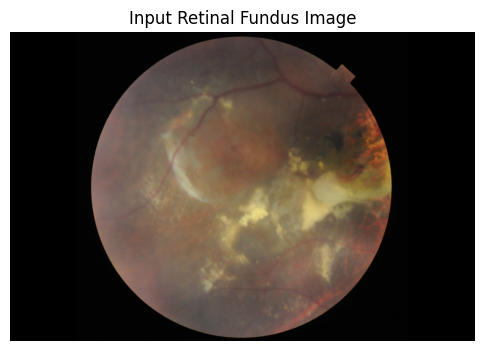


MODULE 1 — RETFOUND MULTI-LABEL PREDICTION


,Disease,Probability (%),Threshold (%),Prediction
0,DR,41.419998,55.0,NEGATIVE
1,MH,0.200000,75.0,NEGATIVE
2,ODC,0.070000,15.0,NEGATIVE
3,TSLN,2.400000,75.0,NEGATIVE
4,DN,0.020000,30.0,NEGATIVE
5,ARMD,25.230000,15.0,POSITIVE
6,MYA,0.070000,25.0,NEGATIVE
7,BRVO,0.190000,80.0,NEGATIVE
8,ODP,0.130000,35.0,NEGATIVE
9,Is_Normal,0.060000,90.0,NEGATIVE



FINAL RETFOUND PREDICTION:
  ✓ ARMD  | Probability = 0.2523

MODULE 2 — EXPLAINABLE AI (XAI)
Searching XAI results for: Testing_46

⚠ No XAI visualization found for this image.
Expected directory:
/kaggle/working/XAI_Results_402_Final/visualizations

MODULE 3 — RETRIEVAL-AUGMENTED CLINICAL EVIDENCE
✓ Clean medical evidence corpus loaded
Total evidence chunks: 91

Available columns:
['Evidence_ID', 'Class', 'Condition', 'Source_Type', 'Source_Title', 'URL', 'Purpose', 'PMID', 'Chunk_Number', 'Chunk_Text', 'Chunk_Word_Count']

Disease column: Class
Evidence column: Evidence_ID

------------------------------------------------------------------------------------------
RAG CLINICAL EVIDENCE — ARMD
------------------------------------------------------------------------------------------
Retrieved chunks: 13

Evidence 1
RAG_0000

Evidence 2
RAG_0001

Evidence 3
RAG_0002

FINAL INTEGRATED DIAGNOSIS REPORT

INPUT
Retinal image: Testing_46.png

RETFOUND — PREDICTION
Predicted disease(s): ARMD

In [37]:
# ============================================================
# FINAL INTEGRATED DEMONSTRATION
# RETFound + XAI + RAG
# ============================================================

import os
import sys
import subprocess
import importlib.util
import glob
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from PIL import Image
from torchvision import transforms
from IPython.display import display


# ============================================================
# 1. BASIC SETUP
# ============================================================

print("=" * 90)
print("RETRIEVAL-AUGMENTED RETINAL DISEASE DIAGNOSIS")
print("FINAL INTEGRATED DEMONSTRATION")
print("=" * 90)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("\nDevice:", device)


# ============================================================
# 2. PROJECT DEFINITIONS
# ============================================================

class_names = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

# Same optimized thresholds used in the project
thresholds = {
    "DR": 0.55,
    "MH": 0.75,
    "ODC": 0.15,
    "TSLN": 0.75,
    "DN": 0.30,
    "ARMD": 0.15,
    "MYA": 0.25,
    "BRVO": 0.80,
    "ODP": 0.35,
    "Is_Normal": 0.90
}


# ============================================================
# 3. RETFOUND REPOSITORY
# ============================================================

RETFOUND_REPO = "/kaggle/working/RETFound_MAE"

if not os.path.exists(RETFOUND_REPO):

    print("\nRETFound repository not found.")
    print("Downloading repository...")

    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/rmaphoh/RETFound_MAE.git",
            RETFOUND_REPO
        ],
        check=True
    )

else:

    print("\nRETFound repository already exists.")


# ============================================================
# 4. LOAD RETFOUND ARCHITECTURE
# ============================================================

MODELS_VIT = os.path.join(
    RETFOUND_REPO,
    "models_vit.py"
)

sys.path.insert(0, RETFOUND_REPO)

spec = importlib.util.spec_from_file_location(
    "models_vit_demo",
    MODELS_VIT
)

models_vit_demo = importlib.util.module_from_spec(spec)

sys.modules["models_vit_demo"] = models_vit_demo

spec.loader.exec_module(models_vit_demo)

RETFound_mae = models_vit_demo.RETFound_mae


# ------------------------------------------------------------
# Exact classifier wrapper used in the project
# ------------------------------------------------------------

class RETFoundClassifierDemo(nn.Module):

    def __init__(self, backbone):

        super().__init__()

        self.backbone = backbone


    def forward(self, x):

        features = self.backbone.forward_features(x)

        if (
            features.ndim == 3
            and features.shape[1] == 1
        ):

            features = features[:, 0, :]

        logits = self.backbone.head(features)

        return logits


# ------------------------------------------------------------
# Recreate exact 10-class architecture
# ------------------------------------------------------------

backbone_demo = RETFound_mae(
    img_size=224,
    num_classes=10,
    global_pool=True
)

demo_model = RETFoundClassifierDemo(
    backbone_demo
)


# ============================================================
# 5. LOAD EXISTING BEST CHECKPOINT
# ============================================================

CHECKPOINT_PATH = (
    "/kaggle/input/datasets/"
    "rithika2006/"
    "retfound-best-model-checkpoint/"
    "best_model.pth"
)

print("\nCheckpoint:")
print(CHECKPOINT_PATH)

if not os.path.exists(CHECKPOINT_PATH):

    raise FileNotFoundError(
        "RETFound checkpoint not found."
    )


checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=False
)


# ------------------------------------------------------------
# Extract trained weights
# ------------------------------------------------------------

state = checkpoint["model_state_dict"]

clean_state = {}

for key, value in state.items():

    if key.startswith("module."):

        clean_key = key[len("module."):]

    else:

        clean_key = key

    clean_state[clean_key] = value


# ------------------------------------------------------------
# Load weights
# ------------------------------------------------------------

demo_model.load_state_dict(
    clean_state,
    strict=True
)

demo_model = demo_model.to(device)

demo_model.eval()

print("\n✓ Existing RETFound checkpoint loaded")
print("✓ No training performed")
print("✓ Model weights were not modified")


# ============================================================
# 6. SELECT DEMONSTRATION IMAGE
# ============================================================

DEMO_IMAGE = (
    "/kaggle/input/datasets/"
    "krishba/"
    "retfound-rfmid-10-diseases/"
    "Test/ARMD/"
    "Testing_46.png"
)

if not os.path.exists(DEMO_IMAGE):

    raise FileNotFoundError(
        f"Demo image not found:\n{DEMO_IMAGE}"
    )


image = Image.open(
    DEMO_IMAGE
).convert("RGB")


print("\n" + "=" * 90)
print("INPUT RETINAL IMAGE")
print("=" * 90)

print(
    "Image:",
    os.path.basename(DEMO_IMAGE)
)

plt.figure(figsize=(6, 6))

plt.imshow(image)

plt.axis("off")

plt.title(
    "Input Retinal Fundus Image"
)

plt.show()


# ============================================================
# 7. SAME RETFOUND PREPROCESSING
# ============================================================

demo_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


input_tensor = demo_transform(
    image
).unsqueeze(0).to(device)


# ============================================================
# 8. RETFOUND PREDICTION
# ============================================================

print("\n" + "=" * 90)
print("MODULE 1 — RETFOUND MULTI-LABEL PREDICTION")
print("=" * 90)


with torch.no_grad():

    logits = demo_model(
        input_tensor
    )

    probabilities = torch.sigmoid(
        logits
    )[0].cpu().numpy()


# ============================================================
# 9. FINAL MULTI-LABEL PREDICTION LOGIC
# ============================================================

# Disease classes
predicted_diseases = []

for i, disease in enumerate(class_names):

    if disease == "Is_Normal":

        continue

    if probabilities[i] >= thresholds[disease]:

        predicted_diseases.append(i)


# ------------------------------------------------------------
# Normal handling
# ------------------------------------------------------------

normal_index = class_names.index(
    "Is_Normal"
)


if len(predicted_diseases) > 0:

    predicted_indices = predicted_diseases

elif (
    probabilities[normal_index]
    >= thresholds["Is_Normal"]
):

    predicted_indices = [
        normal_index
    ]

else:

    predicted_indices = [
        int(np.argmax(probabilities))
    ]


predicted_classes = [
    class_names[i]
    for i in predicted_indices
]


# ============================================================
# 10. DISPLAY PREDICTION TABLE
# ============================================================

prediction_rows = []

for i, disease in enumerate(class_names):

    prediction_rows.append({

        "Disease": disease,

        "Probability (%)": round(
            probabilities[i] * 100,
            2
        ),

        "Threshold (%)": round(
            thresholds[disease] * 100,
            2
        ),

        "Prediction": (
            "POSITIVE"
            if i in predicted_indices
            else "NEGATIVE"
        )
    })


prediction_df = pd.DataFrame(
    prediction_rows
)


display(
    prediction_df
)


print("\nFINAL RETFOUND PREDICTION:")

for disease in predicted_classes:

    idx = class_names.index(
        disease
    )

    print(
        f"  ✓ {disease}"
        f"  | Probability = "
        f"{probabilities[idx]:.4f}"
    )


# ============================================================
# 11. XAI — DISPLAY EXISTING RESULT
# ============================================================

print("\n" + "=" * 90)
print("MODULE 2 — EXPLAINABLE AI (XAI)")
print("=" * 90)


XAI_DIR = (
    "/kaggle/working/"
    "XAI_Results_402_Final/"
    "visualizations"
)


image_id = os.path.splitext(
    os.path.basename(DEMO_IMAGE)
)[0]


print(
    "Searching XAI results for:",
    image_id
)


# Find every saved XAI map for this image
xai_files = glob.glob(
    os.path.join(
        XAI_DIR,
        f"{image_id}_*_XAI.png"
    )
)


if len(xai_files) > 0:

    print(
        f"\n✓ Found {len(xai_files)} "
        "saved XAI visualization(s)"
    )

    for xai_file in sorted(
        xai_files
    ):

        print(
            "\nXAI visualization:",
            os.path.basename(
                xai_file
            )
        )

        xai_image = Image.open(
            xai_file
        )

        display(
            xai_image.resize(
                (700, 700)
            )
        )

else:

    print(
        "\n⚠ No XAI visualization "
        "found for this image."
    )

    print(
        "Expected directory:"
    )

    print(XAI_DIR)


# ============================================================
# 12. RAG — LOAD CLEAN MEDICAL EVIDENCE
# ============================================================

print("\n" + "=" * 90)
print("MODULE 3 — RETRIEVAL-AUGMENTED CLINICAL EVIDENCE")
print("=" * 90)


CORPUS_PATH = (
    "/kaggle/working/"
    "Integrated_RETFound_XAI_RAG/"
    "RAG/"
    "clean_medical_evidence_corpus.csv"
)


if not os.path.exists(
    CORPUS_PATH
):

    print(
        "⚠ Clean medical evidence "
        "corpus not found."
    )

    corpus_df = None

else:

    corpus_df = pd.read_csv(
        CORPUS_PATH
    )

    print(
        "✓ Clean medical evidence "
        "corpus loaded"
    )

    print(
        "Total evidence chunks:",
        len(corpus_df)
    )


# ============================================================
# 13. RAG EVIDENCE RETRIEVAL
# ============================================================

if corpus_df is not None:

    print(
        "\nAvailable columns:"
    )

    print(
        list(corpus_df.columns)
    )


    # --------------------------------------------------------
    # Automatically identify useful columns
    # --------------------------------------------------------

    disease_column = None
    text_column = None


    for column in corpus_df.columns:

        column_name = str(
            column
        ).lower()

        if disease_column is None:

            if (
                "class" in column_name
                or "disease" in column_name
                or "label" in column_name
            ):

                disease_column = column


    for column in corpus_df.columns:

        column_name = str(
            column
        ).lower()

        if text_column is None:

            if (
                "text" in column_name
                or "content" in column_name
                or "chunk" in column_name
                or "evidence" in column_name
            ):

                text_column = column


    print(
        "\nDisease column:",
        disease_column
    )

    print(
        "Evidence column:",
        text_column
    )


    # --------------------------------------------------------
    # Retrieve evidence
    # --------------------------------------------------------

    if (
        disease_column is not None
        and text_column is not None
    ):

        for disease in predicted_classes:

            print(
                "\n" + "-" * 90
            )

            print(
                f"RAG CLINICAL EVIDENCE — "
                f"{disease}"
            )

            print(
                "-" * 90
            )


            mask = (

                corpus_df[
                    disease_column
                ]
                .astype(str)
                .str.upper()
                .str.contains(
                    disease.upper(),
                    na=False
                )

            )


            evidence_df = corpus_df[
                mask
            ]


            print(
                "Retrieved chunks:",
                len(evidence_df)
            )


            if len(evidence_df) > 0:

                for n, (_, row) in enumerate(
                    evidence_df.head(3).iterrows(),
                    start=1
                ):

                    print(
                        f"\nEvidence {n}"
                    )

                    print(
                        str(
                            row[text_column]
                        )[:1500]
                    )

            else:

                print(
                    "No directly matching "
                    "evidence chunk found."
                )

    else:

        print(
            "\n⚠ Could not automatically "
            "identify the RAG columns."
        )


# ============================================================
# 14. FINAL INTEGRATED RESULT
# ============================================================

print("\n" + "=" * 90)
print("FINAL INTEGRATED DIAGNOSIS REPORT")
print("=" * 90)


print(
    "\nINPUT"
)

print(
    "Retinal image:",
    os.path.basename(
        DEMO_IMAGE
    )
)


print(
    "\nRETFOUND — PREDICTION"
)

print(
    "Predicted disease(s):",
    ", ".join(
        predicted_classes
    )
)


print(
    "\nXAI — VISUAL EXPLANATION"
)

if len(xai_files) > 0:

    print(
        "✓ Disease-specific "
        "XAI visualization available"
    )

else:

    print(
        "⚠ XAI visualization "
        "not found"
    )


print(
    "\nRAG — CLINICAL EVIDENCE"
)

if corpus_df is not None:

    print(
        "✓ Clinical evidence corpus loaded"
    )

else:

    print(
        "⚠ Clinical evidence unavailable"
    )


print("\n" + "=" * 90)

print(
    """
                    FINAL SYSTEM

                  RETINAL IMAGE
                        │
                        ▼
                 ┌─────────────┐
                 │  RETFound   │
                 └──────┬──────┘
                        │
                 Disease Prediction
                        │
              ┌─────────┴─────────┐
              ▼                   ▼
          ┌───────┐           ┌───────┐
          │  XAI  │           │  RAG  │
          └───┬───┘           └───┬───┘
              │                   │
       Visual Explanation    Clinical Evidence
              │                   │
              └─────────┬─────────┘
                        ▼
               INTEGRATED REPORT

       Prediction + XAI + Clinical Evidence
"""
)

print("=" * 90)
print("FINAL DEMONSTRATION COMPLETE")
print("=" * 90)

In [38]:
# ============================================================
# CHECK EXISTING PROJECT RESULTS
# ============================================================

import os

print("=" * 80)
print("CHECKING EXISTING PROJECT RESULTS")
print("=" * 80)

# Main working directory
WORK_DIR = "/kaggle/working"

# Important result locations
paths_to_check = [
    "/kaggle/working/XAI_Results_402_Final",
    "/kaggle/working/XAI_Results_402_Final/visualizations",
    "/kaggle/working/Integrated_RETFound_XAI_RAG",
    "/kaggle/working/Integrated_RETFound_XAI_RAG/RAG",
    "/kaggle/working/Integrated_RETFound_XAI_RAG/RAG/clean_medical_evidence_corpus.csv"
]

for path in paths_to_check:

    print("\n" + "-" * 80)

    if os.path.exists(path):

        print("✓ EXISTS:")
        print(path)

        if os.path.isdir(path):

            items = os.listdir(path)

            print(
                "Number of items:",
                len(items)
            )

            print("Contents:")

            for item in sorted(items)[:30]:

                print("   -", item)

            if len(items) > 30:

                print(
                    f"   ... and {len(items)-30} more"
                )

        else:

            size_mb = (
                os.path.getsize(path)
                / (1024 * 1024)
            )

            print(
                f"File size: {size_mb:.2f} MB"
            )

    else:

        print("✗ NOT FOUND:")
        print(path)


print("\n" + "=" * 80)
print("RESULT CHECK COMPLETE")
print("=" * 80)

CHECKING EXISTING PROJECT RESULTS

--------------------------------------------------------------------------------
✗ NOT FOUND:
/kaggle/working/XAI_Results_402_Final

--------------------------------------------------------------------------------
✗ NOT FOUND:
/kaggle/working/XAI_Results_402_Final/visualizations

--------------------------------------------------------------------------------
✓ EXISTS:
/kaggle/working/Integrated_RETFound_XAI_RAG
Number of items: 4
Contents:
   - RAG
   - RAG_evidence_quality_audit.csv
   - Reports
   - XAI

--------------------------------------------------------------------------------
✓ EXISTS:
/kaggle/working/Integrated_RETFound_XAI_RAG/RAG
Number of items: 1
Contents:
   - clean_medical_evidence_corpus.csv

--------------------------------------------------------------------------------
✓ EXISTS:
/kaggle/working/Integrated_RETFound_XAI_RAG/RAG/clean_medical_evidence_corpus.csv
File size: 0.07 MB

RESULT CHECK COMPLETE


In [40]:
# ============================================================
# INSPECT INTEGRATED PROJECT RESULTS
# ============================================================

import os

BASE = "/kaggle/working/Integrated_RETFound_XAI_RAG"

folders = [
    os.path.join(BASE, "XAI"),
    os.path.join(BASE, "Reports"),
    os.path.join(BASE, "RAG")
]

print("=" * 90)
print("INTEGRATED PROJECT — EXISTING RESULTS")
print("=" * 90)

for folder in folders:

    print("\n" + "=" * 90)
    print("FOLDER:", folder)
    print("=" * 90)

    if not os.path.exists(folder):

        print("❌ NOT FOUND")
        continue

    for root, dirs, files in os.walk(folder):

        level = root.replace(folder, "").count(os.sep)
        indent = "    " * level

        print(f"\n{indent}{os.path.basename(root)}/")

        for file in sorted(files):

            file_path = os.path.join(root, file)

            size_kb = (
                os.path.getsize(file_path)
                / 1024
            )

            print(
                f"{indent}    └── {file}"
                f"  ({size_kb:.1f} KB)"
            )

print("\n" + "=" * 90)
print("INSPECTION COMPLETE")
print("=" * 90)

INTEGRATED PROJECT — EXISTING RESULTS

FOLDER: /kaggle/working/Integrated_RETFound_XAI_RAG/XAI

XAI/

FOLDER: /kaggle/working/Integrated_RETFound_XAI_RAG/Reports

Reports/

FOLDER: /kaggle/working/Integrated_RETFound_XAI_RAG/RAG

RAG/
    └── clean_medical_evidence_corpus.csv  (70.2 KB)

INSPECTION COMPLETE


In [41]:
# ============================================================
# FIND ALL EXISTING RETFOUND / XAI / REPORT FILES
# ============================================================

import os

print("=" * 90)
print("SEARCHING KAGGLE INPUT DATASETS FOR EXISTING PROJECT RESULTS")
print("=" * 90)

SEARCH_ROOT = "/kaggle/input"

keywords = [
    "xai",
    "report",
    "result",
    "summary",
    "prediction",
    "retfound",
    "visual",
    "testing"
]

found = []

for root, dirs, files in os.walk(SEARCH_ROOT):

    for file in files:

        filename = file.lower()

        if any(
            keyword in filename
            for keyword in keywords
        ):

            full_path = os.path.join(root, file)

            size_kb = (
                os.path.getsize(full_path)
                / 1024
            )

            found.append(
                (full_path, size_kb)
            )


print(
    f"\nFound {len(found)} potentially relevant files.\n"
)

for path, size_kb in found:

    print(
        f"{path}  ({size_kb:.1f} KB)"
    )

print("\n" + "=" * 90)
print("SEARCH COMPLETE")
print("=" * 90)

SEARCHING KAGGLE INPUT DATASETS FOR EXISTING PROJECT RESULTS

Found 669 potentially relevant files.

/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_140.png  (1675.7 KB)
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_265.png  (1729.6 KB)
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_356.png  (1628.8 KB)
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_507.png  (6478.2 KB)
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_473.png  (6310.3 KB)
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_492.png  (5788.3 KB)
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_180.png  (1686.0 KB)
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_111.png  (1685.7 KB)
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_373.png  (1700.7 KB)
/kaggle/

In [42]:
# ============================================================
# INSPECT EXISTING XAI RESULTS ONLY
# ============================================================

import os

XAI_ROOT = "/kaggle/input/notebooks/rithika2006/xai-component-of-retinal-project"

print("=" * 90)
print("EXISTING XAI RESULTS")
print("=" * 90)

for root, dirs, files in os.walk(XAI_ROOT):

    level = root.replace(XAI_ROOT, "").count(os.sep)

    if level > 2:
        continue

    indent = "    " * level

    print(f"\n{indent}{os.path.basename(root)}/")

    for file in files:
        size_kb = os.path.getsize(
            os.path.join(root, file)
        ) / 1024

        print(
            f"{indent}    {file} ({size_kb:.1f} KB)"
        )

print("\n" + "=" * 90)
print("XAI INSPECTION COMPLETE")
print("=" * 90)

EXISTING XAI RESULTS

xai-component-of-retinal-project/
    __results__.html (1150.5 KB)
    __notebook__.ipynb (4776.1 KB)
    __output__.json (1.6 KB)
    custom.css (0.0 KB)

    __results___files/
        __results___68_7.png (457.6 KB)
        __results___68_9.png (483.9 KB)
        __results___68_1.png (451.4 KB)
        __results___68_11.png (461.5 KB)
        __results___68_5.png (423.0 KB)
        __results___68_3.png (448.0 KB)
        __results___68_13.png (466.9 KB)

XAI INSPECTION COMPLETE


In [43]:
# ============================================================
# INSPECT EXISTING XAI NOTEBOOK
# ============================================================

import json
import os

NOTEBOOK_PATH = (
    "/kaggle/input/notebooks/"
    "rithika2006/xai-component-of-retinal-project/"
    "__notebook__.ipynb"
)

print("=" * 90)
print("INSPECTING EXISTING XAI NOTEBOOK")
print("=" * 90)

with open(NOTEBOOK_PATH, "r", encoding="utf-8") as f:
    nb = json.load(f)

cells = nb.get("cells", [])

print("Total cells:", len(cells))

print("\nSearching for important XAI operations...\n")

keywords = [
    "save",
    "visualization",
    "Testing_",
    "generate_xai",
    "heatmap",
    "attribution",
    "test",
    "XAI"
]

for i, cell in enumerate(cells):

    source = "".join(cell.get("source", []))

    matches = [
        k for k in keywords
        if k.lower() in source.lower()
    ]

    if matches:
        print("-" * 90)
        print("CELL:", i)
        print("MATCHES:", matches)
        print("-" * 90)

        # Print only the first 40 lines of each relevant cell
        lines = source.splitlines()

        for line in lines[:40]:
            print(line)

        if len(lines) > 40:
            print("...")

print("\n" + "=" * 90)
print("XAI NOTEBOOK INSPECTION COMPLETE")
print("=" * 90)

INSPECTING EXISTING XAI NOTEBOOK
Total cells: 69

Searching for important XAI operations...

------------------------------------------------------------------------------------------
CELL: 0
MATCHES: ['save']
------------------------------------------------------------------------------------------
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to